# Chapitre 12 - Cours 3 : discriminants flexibles (FDA, PDA, MDA)

La seconde moitié du chapitre (sections 12.4 à 12.7) généralise l'analyse discriminante
linéaire (LDA, section 4.3) dans trois directions :

1. **FDA** (*flexible discriminant analysis*) : on réécrit la LDA comme une suite de
   **régressions** (*optimal scoring*), puis on remplace la régression linéaire par une
   régression non paramétrique ;
2. **PDA** (*penalized discriminant analysis*) : on **pénalise** les coefficients quand les
   variables sont nombreuses et corrélées (signaux, images) ;
3. **MDA** (*mixture discriminant analysis*) : chaque classe est un **mélange** de gaussiennes
   de covariance commune, estimé par l'algorithme EM.

Exemples : deux gaussiennes emboîtées (figure 12.9), la simulation « mixture »
(figure 12.13) et les données *waveform* (figures 12.14–12.15, tableau 12.4).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch12_svm import (LDA, QDA, FDA, MDA, class_indicator, poly_basis, rbf_kernel,
                          second_diff_penalty, simulate_mixture, mixture_bayes_prob,
                          plot_mixture_boundary, waveform_h, simulate_waveform,
                          waveform_bayes_posterior)
set_style()

## 1. Pourquoi généraliser la LDA ?

La LDA est simple et souvent efficace, mais (section 12.4 du livre) :

* ses frontières sont **linéaires**, ce qui est parfois trop rigide ;
* un **seul prototype** (centroïde) par classe peut être insuffisant pour des classes
  hétérogènes ;
* avec **beaucoup de variables corrélées** (pixels, fréquences), elle estime trop de
  paramètres avec une grande variance.

Les trois réponses (FDA, PDA, MDA) reposent sur un même lien entre LDA et régression.

## 2. LDA et *optimal scoring*

Supposons $K$ classes $\mathcal G = \{1,\dots,K\}$. On cherche une fonction de **scores**
$\theta : \mathcal G\to\mathbb R$ telle que les étiquettes transformées $\theta(g_i)$ soient
le mieux possible prédites par une régression linéaire sur $x$ (éq. (12.52)) :

$$\min_{\beta,\theta}\sum_{i=1}^N\left(\theta(g_i) - x_i^T\beta\right)^2,$$

avec des contraintes sur $\theta$ (moyenne nulle, variance unité sur l'échantillon) pour
exclure la solution triviale $\theta = 0$, $\beta = 0$.

Plus généralement, on cherche $L \le K-1$ couples (scores $\theta_\ell$, coefficients
$\beta_\ell$) minimisant le **résidu quadratique moyen** (12.53)

$$\mathrm{ASR} = \frac1N\sum_{\ell=1}^L\sum_{i=1}^N\left(\theta_\ell(g_i) - x_i^T\beta_\ell\right)^2,$$

les scores étant orthonormés pour un produit scalaire convenable.

**Résultat (exercices 12.6 et 12.8).** Les $\beta_\ell$ sont proportionnels aux directions
discriminantes $\nu_\ell$ de la LDA (section 4.3.3), et la distance de Mahalanobis d'un point
$x$ au centroïde $\hat\mu_k$ s'écrit (12.54)–(12.55)

$$\delta_J(x, \hat\mu_k) = \sum_{\ell=1}^{K-1}w_\ell\left(\hat\eta_\ell(x) - \bar\eta_\ell^k\right)^2 + D(x),\qquad w_\ell = \frac{1}{r_\ell^2(1-r_\ell^2)},$$

où $\hat\eta_\ell(x) = x^T\beta_\ell$, $\bar\eta_\ell^k$ est sa moyenne dans la classe $k$,
$r_\ell^2$ le résidu quadratique moyen du $\ell$-ième ajustement, et $D(x)$ ne dépend pas de $k$.

> **À retenir.** La LDA = une suite de régressions linéaires + un classement au centroïde le
> plus proche dans l'espace des valeurs ajustées.

### 2.1 Algorithme (section 12.5.1)

Soit $Y$ la matrice indicatrice $N\times K$ ($y_{ik} = 1$ si $g_i = k$) et
$D_\pi = Y^TY/N$ la matrice diagonale des proportions de classes.

1. **Régression multivariée** : on régresse $Y$ sur $x$ (ou sur une base $h(x)$) ; on note
   $S$ l'opérateur linéaire de lissage, $\hat Y = SY$ et $\eta^*(x)$ les fonctions ajustées.
2. **Scores optimaux** : on diagonalise $Y^T\hat Y = Y^TSY$ avec la normalisation
   $\Theta^TD_\pi\Theta = I$ (problème aux valeurs propres généralisé
   $\frac1NY^TSY\theta = \alpha^2D_\pi\theta$).
3. **Mise à jour** : $\eta(x) = \Theta^T\eta^*(x)$. La première solution (constante,
   $\alpha^2 = 1$) est triviale ; les $K-1$ suivantes sont les fonctions discriminantes.

Ici $\alpha_\ell^2 = 1 - r_\ell^2$ est la part de variance des scores expliquée par la
régression. La classe `FDA` du module `esl.ch12_svm` implémente ces trois étapes.

### 2.2 Vérification : FDA avec régression linéaire = LDA

Sur les données *waveform* (3 classes, 21 variables), on compare les distances (12.54) de
la FDA aux distances de Mahalanobis exactes, calculées avec la covariance intra-classe
$W$ (normalisée par $N$). Leur différence doit être constante en $k$ : c'est le terme $D(x)$.

In [2]:
Xw, gw = datasets.load_waveform("train")
Xwt, gwt = datasets.load_waveform("test")
fda_lin = FDA().fit(Xw, gw)
lda = LDA().fit(Xw, gw)
N, K = len(gw), 3
W_N = lda.W_ * (N - K) / N
Wi = np.linalg.inv(W_N)
maha = np.column_stack([np.einsum("ij,jk,ik->i", Xwt - m, Wi, Xwt - m) for m in lda.means_])
diff = fda_lin.distances(Xwt) + 2 * np.log(fda_lin.priors_) - maha
print("variation de la différence entre classes (doit être ~0) : %.2e" % diff.std(axis=1).max())
print("alpha_l^2 =", fda_lin.eigvals_.round(4), "   poids w_l =", fda_lin.weights_.round(3))

variation de la différence entre classes (doit être ~0) : 9.01e-14
alpha_l^2 = [0.54   0.4394]    poids w_l = [4.026 4.06 ]


Et les coefficients $\beta_\ell$ de l'*optimal scoring* sont colinéaires aux directions
canoniques $\nu_\ell$ de la LDA (cosinus égal à $\pm1$) :

In [3]:
V, _ = lda.canonical_directions()
for l in range(2):
    b, v = fda_lin.beta_[1:, l], V[:, l]
    print("direction %d : cos(beta, nu) = %+.6f" % (l + 1, b @ v / np.linalg.norm(b) / np.linalg.norm(v)))
print("désaccord de classement FDA linéaire / LDA sur le test : %.3f"
      % np.mean(fda_lin.predict(Xwt) != lda.predict(Xwt)))

direction 1 : cos(beta, nu) = -1.000000
direction 2 : cos(beta, nu) = -1.000000
désaccord de classement FDA linéaire / LDA sur le test : 0.002


(Le très léger désaccord vient seulement de la normalisation de $W$ par $N$ ou par $N - K$,
qui change le poids relatif du terme $-2\log\hat\pi_k$.)

## 3. FDA : remplacer la régression linéaire

L'intérêt de la reformulation est de pouvoir remplacer $x^T\beta_\ell$ par des ajustements
**non paramétriques** $\eta_\ell(x)$ (modèles additifs, splines, MARS, noyaux…) en minimisant
(12.56) :

$$\mathrm{ASR}(\{\theta_\ell, \eta_\ell\}) = \frac1N\sum_{\ell=1}^L\left[\sum_{i=1}^N(\theta_\ell(g_i) - \eta_\ell(x_i))^2 + \lambda J(\eta_\ell)\right].$$

Si l'on régresse sur une base agrandie $h(x)$, la FDA est une LDA **dans l'espace agrandi** :
des frontières linéaires en $h(x)$ deviennent non linéaires en $x$ - exactement le paradigme
des SVM.

### 3.1 Deux gaussiennes emboîtées (figure 12.9)

50 points de $N(0, I)$ et 50 de $N(0, \frac94 I)$ dans $\mathbb R^2$. Avec une régression
polynomiale de degré 2, la FDA produit une frontière quadratique (une ellipse).

**Frontière de Bayes.** Pour $N(0,I)$ contre $N(0,cI)$ en dimension $p$ avec probabilités
égales, on compare les log-densités :
$-\frac{\|x\|^2}2 = -\frac{\|x\|^2}{2c} - \frac p2\log c$, soit
$\|x\|^2\left(1 - \frac1c\right) = p\log c$, c'est-à-dire le cercle
$\|x\| = \sqrt{\frac{p\,c\log c}{c-1}}$.

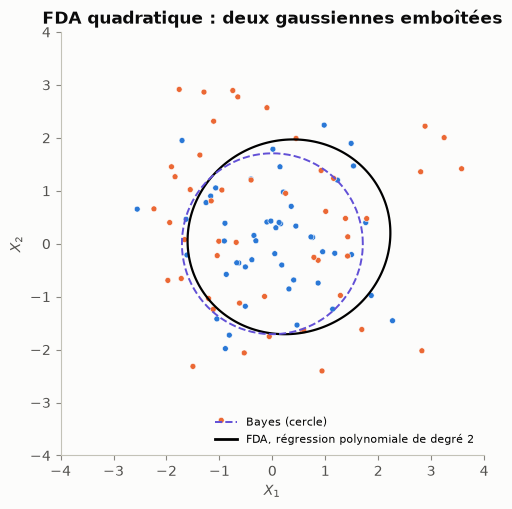

In [4]:
rng = np.random.RandomState(0)
c = 9 / 4
Xg = np.vstack([rng.randn(50, 2), np.sqrt(c) * rng.randn(50, 2)])
gg = np.r_[np.zeros(50, int), np.ones(50, int)]
fda_q = FDA(basis=lambda Z: poly_basis(Z, 2)).fit(Xg, gg)
xx, yy = np.meshgrid(np.linspace(-4, 4, 300), np.linspace(-4, 4, 300))
dist = fda_q.distances(np.c_[xx.ravel(), yy.ravel()])
Fq = (dist[:, 0] - dist[:, 1]).reshape(xx.shape)
r_bayes = np.sqrt(2 * c * np.log(c) / (c - 1))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(Xg[:, 0], Xg[:, 1], c=gg, cmap=TWO_CLASS, s=18, edgecolor="white", lw=0.4)
ax.contour(xx, yy, Fq, levels=[0], colors="k", linewidths=1.6)
tt = np.linspace(0, 2 * np.pi, 200)
ax.plot(r_bayes * np.cos(tt), r_bayes * np.sin(tt), color=COLORS[6], ls="--", lw=1.4, label="Bayes (cercle)")
ax.plot([], [], color="k", label="FDA, régression polynomiale de degré 2")
ax.set_aspect("equal"); ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.grid(False)
ax.set_title("FDA quadratique : deux gaussiennes emboîtées")
ax.legend(loc="lower right", fontsize=8)
plt.show()

### 3.2 FDA sur la simulation « mixture » (figure 12.13, en haut)

Le livre utilise MARS comme méthode de régression (chapitre 9). Pour rester dans l'esprit du
chapitre, nous utilisons ici une **régression ridge sur une base radiale**
$h_j(x) = \exp(-\gamma\|x - x_j\|^2)$ centrée aux points d'apprentissage ($\gamma = 1$,
$\lambda = 1$) - c'est la régression à noyau de la section 12.3.7. Avec $K=2$ classes, il n'y
a qu'une fonction discriminante.

In [5]:
mix = datasets.load_mixture_example()
Xm, gm = mix["x"], mix["y"]
rng = np.random.RandomState(0)
Xmt, gmt = simulate_mixture(5000, mix["means"], rng)
bayes_mix = np.mean((mixture_bayes_prob(Xmt, mix["means"]) > 0.5) != gmt)
fda_rbf = FDA(basis=lambda Z: rbf_kernel(Z, Xm, 1.0), lam=1.0).fit(Xm, gm)
mda_mix = MDA(n_sub=5, n_iter=100, rng=np.random.RandomState(0)).fit(Xm, gm)
for name, mod in [("FDA / base radiale", fda_rbf), ("MDA, 5 sous-classes", mda_mix)]:
    print("%-20s : erreur app. %.3f, test %.3f" % (name, np.mean(mod.predict(Xm) != gm), np.mean(mod.predict(Xmt) != gmt)))
print("erreur de Bayes      : %.3f" % bayes_mix)

FDA / base radiale   : erreur app. 0.155, test 0.217
MDA, 5 sous-classes  : erreur app. 0.160, test 0.218
erreur de Bayes      : 0.210
